# Heart Disease Classification

**Goal:** predict whether a patient has heart disease from 13 clinical measurements, and evaluate the model honestly.

**Two key insights of this project**
1. **~70% of the rows are duplicates.** A naive train/test split puts the same patient in both sets, which inflates accuracy (a KNN reaches ~90%). Section 3 demonstrates this.
2. **The `target` column in this file is reversed.** In this Kaggle/UCI version `target = 1` means *no* disease and `0` means disease (verified in section 2 against cardiology risk markers and the original UCI class counts). I define `disease = 1 - target` so that sensitivity, confusion matrices and probabilities refer to the correct class.

*Final results are in the "Conclusions" section at the end.*

## 1. Load data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, RocCurveDisplay, make_scorer, recall_score)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEED = 42

raw = pd.read_csv("data/heart_updated.csv")
print(raw.shape)
raw.head()

(1026, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


**Columns:** `age`; `sex` (1 = male); `cp` chest pain type (0-3); `trestbps` resting blood pressure; `chol` cholesterol; `fbs` fasting blood sugar > 120 (1 = yes); `restecg` resting ECG result (0-2); `thalach` max heart rate achieved; `exang` exercise-induced angina; `oldpeak` ST depression; `slope` ST slope; `ca` number of major vessels (0-4); `thal` thalassemia result; `target` the original 0/1 label, which is **reversed** (see section 2).

## 2. Data quality and label check

In [2]:
print("Missing values:", int(raw.isna().sum().sum()))
n_dup = raw.duplicated().sum()
print(f"Duplicate rows: {n_dup} of {len(raw)} ({n_dup/len(raw):.1%})  ->  unique patients: {len(raw) - n_dup}")

# Suspicious category codes (kept; in the UCI data these codes mark missing values, only a handful of rows)
print("ca == 4 rows:", (raw.drop_duplicates()["ca"] == 4).sum(), "| thal == 0 rows:", (raw.drop_duplicates()["thal"] == 0).sum())

df = raw.drop_duplicates().reset_index(drop=True)
print("Clean dataset:", df.shape)

Missing values: 0
Duplicate rows: 723 of 1026 (70.5%)  ->  unique patients: 303
ca == 4 rows: 4 | thal == 0 rows: 2
Clean dataset: (303, 14)


### Label check: is `target = 1` really "disease"?

Patients **with** coronary disease typically have a **lower** maximum heart rate (`thalach`), more exercise-induced angina (`exang`), larger ST depression (`oldpeak`), more narrowed vessels (`ca`) and are more often male. If `target = 1` meant disease, those markers would point that way in the `target = 1` group. I also compare the class counts with the original UCI Cleveland data (164 patients without disease and 139 with disease, out of 303).

In [3]:
markers = df.groupby("target").agg(max_heart_rate=("thalach", "mean"), exercise_angina_rate=("exang", "mean"),
                                  st_depression=("oldpeak", "mean"), narrowed_vessels=("ca", "mean"), male_share=("sex", "mean")).round(2)
print(markers)
print("\nClass counts in this file:", df["target"].value_counts().to_dict(), "| UCI Cleveland: 164 without disease, 139 with disease")
print("\nThe target=1 group has a HIGHER heart rate and FEWER disease markers, and its size (165) matches the 164 disease-free")
print("Cleveland patients. So target = 1 means NO disease: the label is reversed. Flipping it:")
df["disease"] = 1 - df["target"]
print(df["disease"].value_counts().rename({1: "disease", 0: "no disease"}).to_dict(), f"| disease prevalence {df['disease'].mean():.1%}")

        max_heart_rate  exercise_angina_rate  st_depression  narrowed_vessels  \
target                                                                          
0               139.10                  0.55           1.59              1.17   
1               158.33                  0.14           0.59              0.34   

        male_share  
target              
0             0.83  
1             0.56  

Class counts in this file: {1: 165, 0: 138} | UCI Cleveland: 164 without disease, 139 with disease

The target=1 group has a HIGHER heart rate and FEWER disease markers, and its size (165) matches the 164 disease-free
Cleveland patients. So target = 1 means NO disease: the label is reversed. Flipping it:
{'no disease': 165, 'disease': 138} | disease prevalence 45.5%


## 3. Why duplicates matter: the data-leakage demo

The common workflow (random split, then KNN) gives a high score on the raw data. I repeat it on the raw and the deduplicated data, using the **same unscaled KNN**, to show how much of the score comes from duplicates.

In [4]:
raw["disease"] = 1 - raw["target"]

def knn_split_accuracy(data, k):
    X, y = data.drop(columns=["target", "disease"]), data["disease"]
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=SEED)
    acc = KNeighborsClassifier(n_neighbors=k).fit(Xtr, ytr).score(Xte, yte)
    # how many test rows have an exact copy in the training set?
    train_keys = set(map(tuple, Xtr.values))
    leaked = np.mean([tuple(r) in train_keys for r in Xte.values])
    return acc, leaked

rows = []
for name, data in [("Raw (with duplicates)", raw), ("Deduplicated", df)]:
    for k in (3, 5):
        acc, leaked = knn_split_accuracy(data, k)
        rows.append({"data": name, "k": k, "test_accuracy": round(acc, 3), "test_rows_with_exact_copy_in_train": f"{leaked:.0%}"})
pd.DataFrame(rows)

,data,k,test_accuracy,test_rows_with_exact_copy_in_train
0,Raw (with duplicates),3,0.903,97%
1,Raw (with duplicates),5,0.748,97%
2,Deduplicated,3,0.623,0%
3,Deduplicated,5,0.623,0%


On the raw data a large share of the test rows have an identical twin in the training set, so the model is mostly *remembering*, not generalising. This also explains the odd jump between K=3 and K=5 on the raw data: K=3 memorises copies better. On clean data the score drops sharply. All results below use the deduplicated data.

## 4. Exploratory analysis

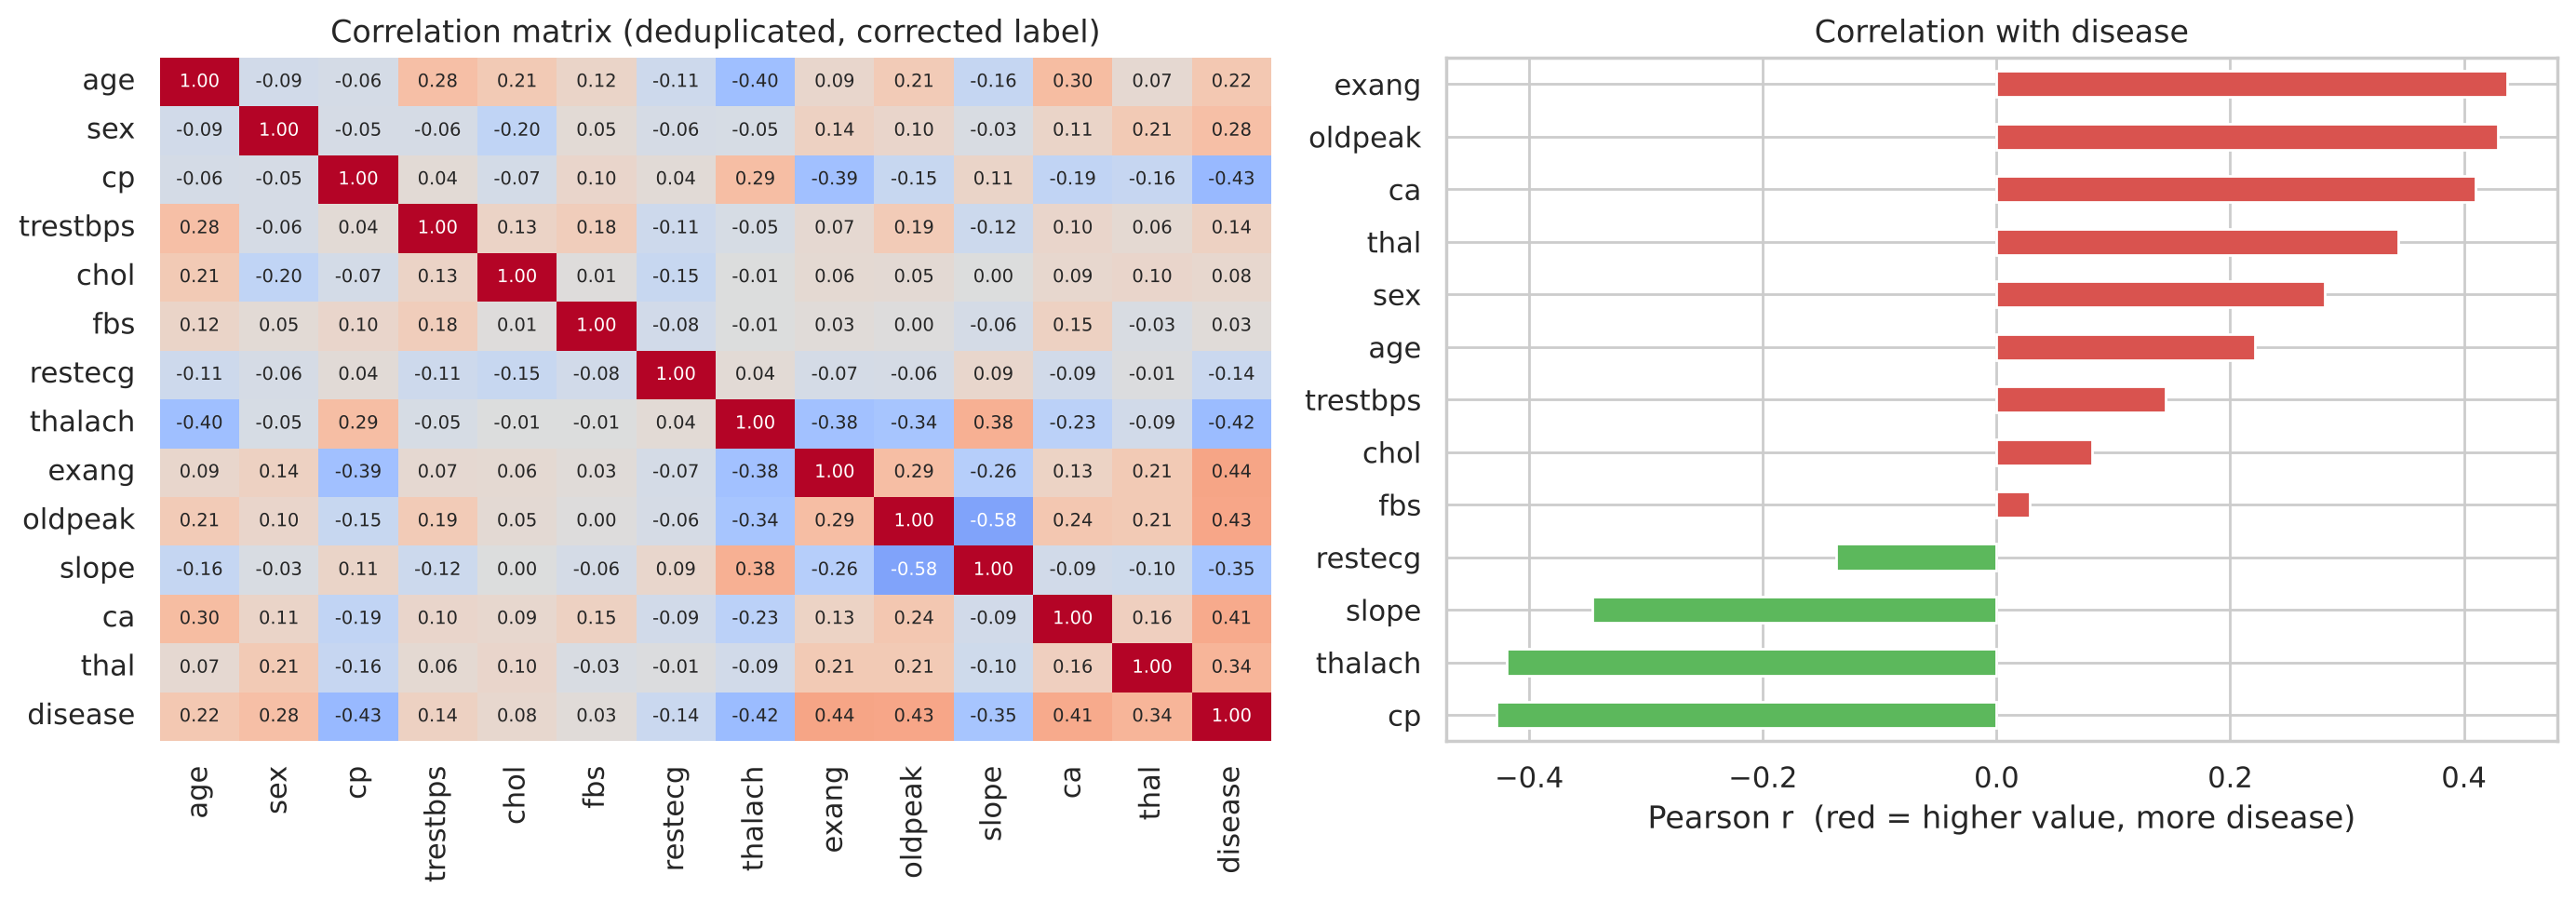

In [5]:
eda = df.drop(columns="target")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[0], annot_kws={"size": 7}, cbar=False)
axes[0].set_title("Correlation matrix (deduplicated, corrected label)")
corr_t = eda.corr()["disease"].drop("disease").sort_values()
corr_t.plot.barh(ax=axes[1], color=["#5cb85c" if v < 0 else "#d9534f" for v in corr_t])
axes[1].set_title("Correlation with disease"); axes[1].set_xlabel("Pearson r  (red = higher value, more disease)")
plt.tight_layout(); plt.show()

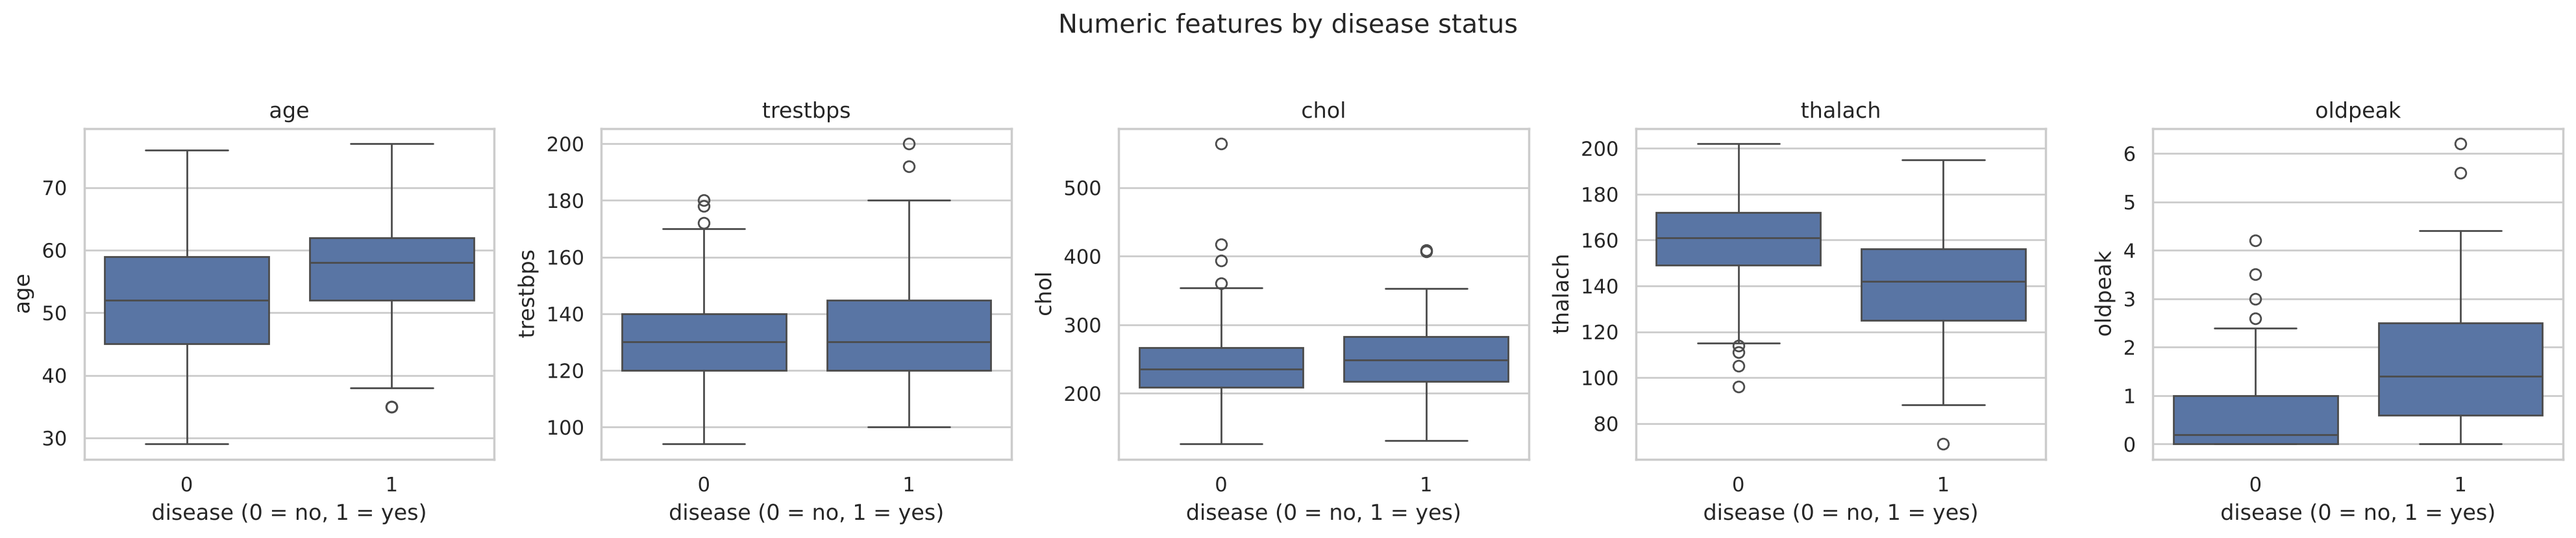

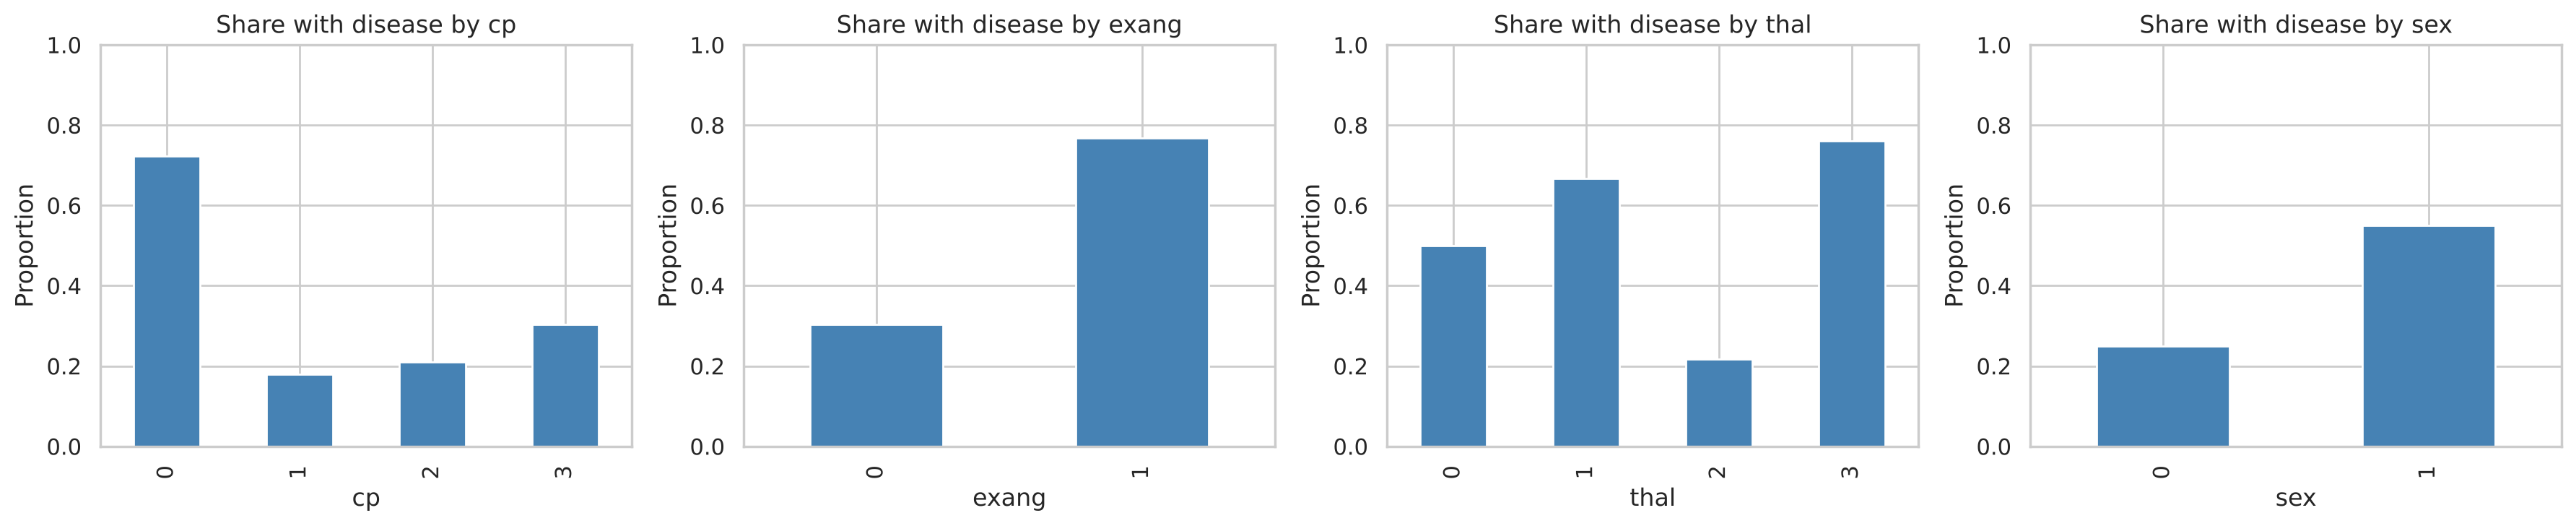

In [6]:
num_cols = ["age", "trestbps", "chol", "thalach", "oldpeak"]
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, c in zip(axes, num_cols):
    sns.boxplot(data=df, x="disease", y=c, ax=ax)
    ax.set_title(c); ax.set_xlabel("disease (0 = no, 1 = yes)")
plt.suptitle("Numeric features by disease status", y=1.03); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, ["cp", "exang", "thal", "sex"]):
    df.groupby(c)["disease"].mean().plot.bar(ax=ax, color="steelblue")
    ax.set_title(f"Share with disease by {c}"); ax.set_ylabel("Proportion"); ax.set_ylim(0, 1)
plt.tight_layout(); plt.show()

## 5. Modelling

- **Stratified** 80/20 split (keeps class balance); the test set is touched only once, at the end.
- A `Pipeline` so that scaling/encoding is fitted **only on training folds** (no preprocessing leakage). KNN needs scaled features.
- Models: KNN (K chosen by cross-validation), Logistic Regression, Random Forest.
- Metrics (positive class = **disease**): accuracy, **sensitivity** (share of sick patients detected; missing a sick patient is the costly error), **specificity** (share of healthy patients correctly cleared), F1 and ROC AUC, averaged over repeated 5-fold CV.
- Majority-class baseline accuracy is the share of the larger class (printed below).

Train: (242, 13) | Test: (61, 13) | majority-class baseline accuracy: 0.545


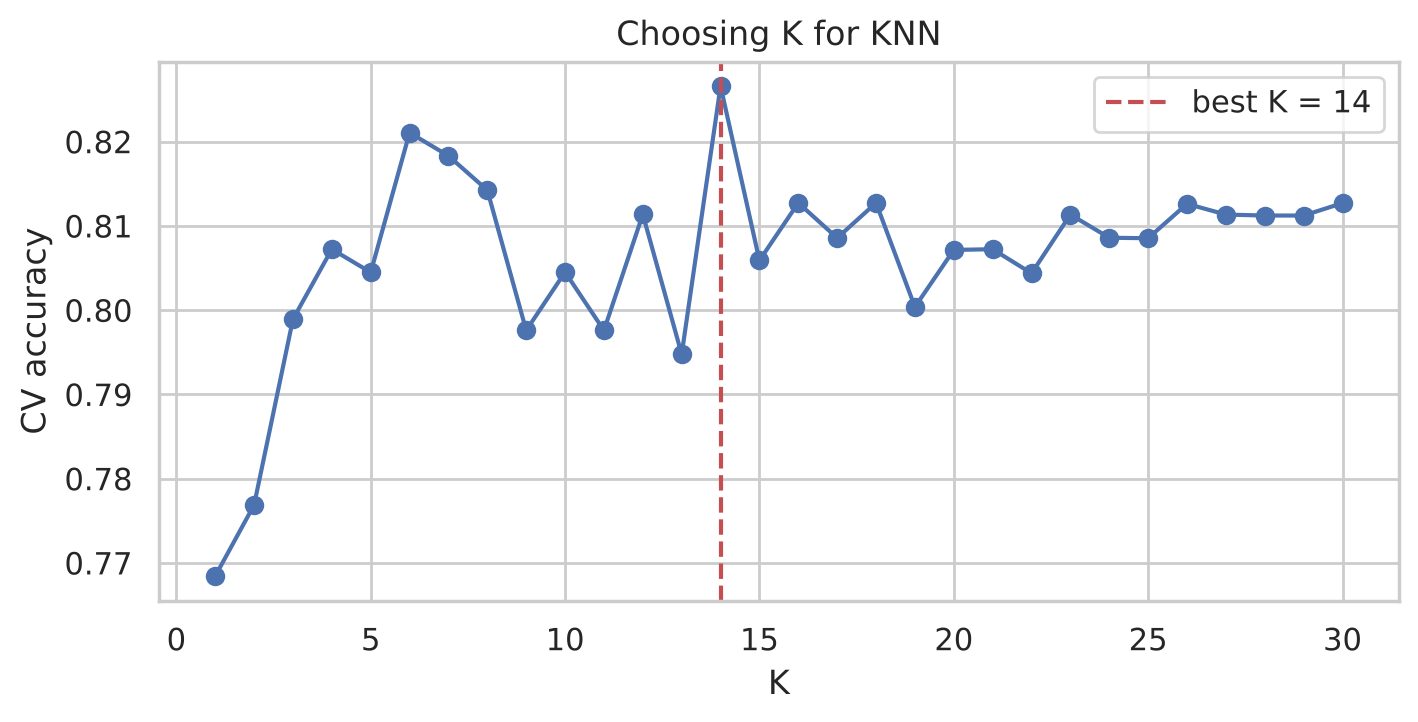

In [7]:
X, y = df.drop(columns=["target", "disease"]), df["disease"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print("Train:", X_train.shape, "| Test:", X_test.shape, "| majority-class baseline accuracy:", round(max(y.mean(), 1 - y.mean()), 3))

num = ["age", "trestbps", "chol", "thalach", "oldpeak"]
cat = ["cp", "restecg", "slope", "thal"]
passthrough_cols = ["sex", "fbs", "exang", "ca"]   # binary flags and the vessel count, used as-is

def preprocessor():
    return ColumnTransformer([
        ("num", StandardScaler(), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
        ("pass", "passthrough", passthrough_cols),
    ])

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

# choose K for KNN by cross-validation
ks = range(1, 31)
knn_scores = [cross_val_score(Pipeline([("pre", preprocessor()), ("m", KNeighborsClassifier(k))]), X_train, y_train, cv=cv).mean() for k in ks]
best_k = list(ks)[int(np.argmax(knn_scores))]
plt.figure(figsize=(8, 3.5)); plt.plot(list(ks), knn_scores, marker="o")
plt.axvline(best_k, color="r", ls="--", label=f"best K = {best_k}")
plt.xlabel("K"); plt.ylabel("CV accuracy"); plt.title("Choosing K for KNN"); plt.legend(); plt.show()

In [8]:
models = {
    f"KNN (K={best_k})": KNeighborsClassifier(n_neighbors=best_k),
    "Logistic Regression": LogisticRegression(max_iter=2000),
    "Random Forest": RandomForestClassifier(n_estimators=300, min_samples_leaf=2, random_state=SEED),
}
specificity = make_scorer(recall_score, pos_label=0)
scoring = {"accuracy": "accuracy", "sensitivity": "recall", "specificity": specificity, "f1": "f1", "roc_auc": "roc_auc"}
rows = []
for name, m in models.items():
    res = cross_validate(Pipeline([("pre", preprocessor()), ("m", m)]), X_train, y_train, cv=cv, scoring=scoring)
    rows.append({"model": name, **{s: res[f"test_{s}"].mean() for s in scoring}, "accuracy_std": res["test_accuracy"].std()})
cv_table = pd.DataFrame(rows).set_index("model").round(3)
cv_table

,accuracy,sensitivity,specificity,f1,roc_auc,accuracy_std
model,,,,,,
KNN (K=14),0.827,0.706,0.927,0.786,0.893,0.042
Logistic Regression,0.839,0.791,0.879,0.816,0.905,0.051
Random Forest,0.844,0.794,0.886,0.822,0.915,0.049


## 6. Final evaluation on the held-out test set

Selected model (best CV ROC AUC): Random Forest
Test accuracy: 0.836 | ROC AUC: 0.917

                precision    recall  f1-score   support

no disease (0)       0.83      0.88      0.85        33
   disease (1)       0.85      0.79      0.81        28

      accuracy                           0.84        61
     macro avg       0.84      0.83      0.83        61
  weighted avg       0.84      0.84      0.84        61

Sensitivity = recall of 'disease (1)'; specificity = recall of 'no disease (0)'.


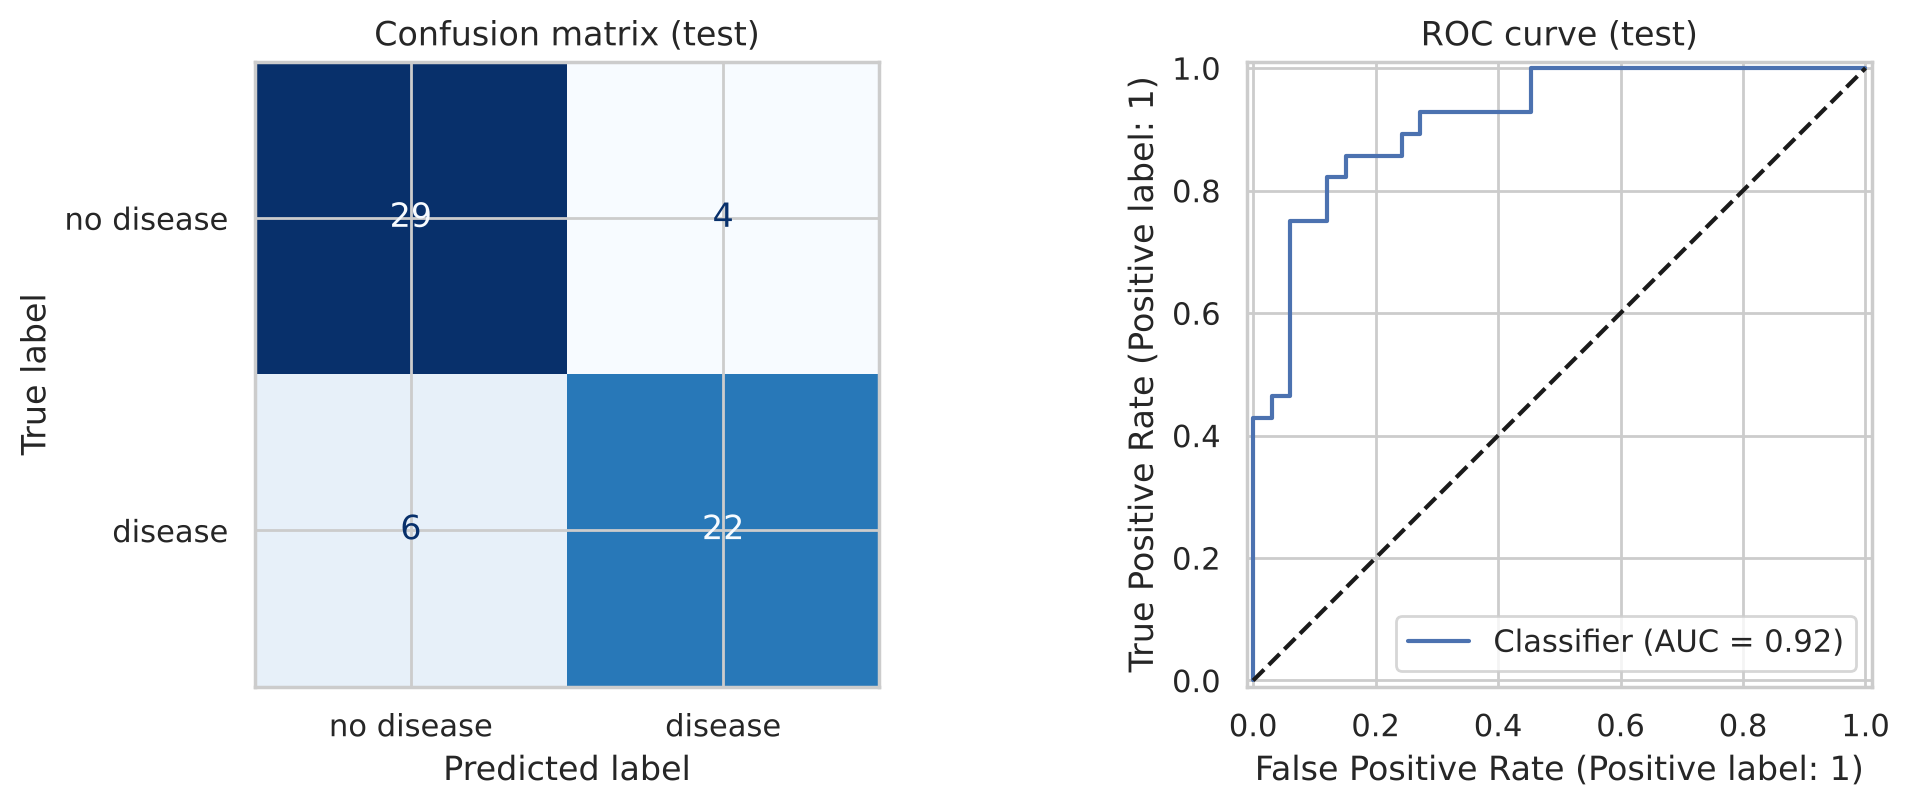

Note: the test set has only 61 patients, so this estimate is noisy; the cross-validated numbers above are more reliable.


In [9]:
best_name = cv_table["roc_auc"].idxmax()
final = Pipeline([("pre", preprocessor()), ("m", models[best_name])]).fit(X_train, y_train)
pred = final.predict(X_test); proba = final.predict_proba(X_test)[:, 1]
print("Selected model (best CV ROC AUC):", best_name)
print(f"Test accuracy: {accuracy_score(y_test, pred):.3f} | ROC AUC: {roc_auc_score(y_test, proba):.3f}\n")
print(classification_report(y_test, pred, target_names=["no disease (0)", "disease (1)"]))
print("Sensitivity = recall of 'disease (1)'; specificity = recall of 'no disease (0)'.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["no disease", "disease"], ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (test)")
RocCurveDisplay.from_predictions(y_test, proba, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "k--"); axes[1].set_title("ROC curve (test)")
plt.tight_layout(); plt.show()
print(f"Note: the test set has only {len(y_test)} patients, so this estimate is noisy; the cross-validated numbers above are more reliable.")

### Robustness: does the model ranking depend on the split?
With only 303 patients a single split is noisy, so I repeat the stratified split 10 times and compare test ROC AUC for the three models.

In [10]:
rob = {k: [] for k in models}; rob_acc = {k: [] for k in models}; imp_runs = []
for s in range(10):
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2, stratify=y, random_state=100 + s)
    for name, m in models.items():
        pipe = Pipeline([("pre", preprocessor()), ("m", clone(m))]).fit(Xa, ya)
        rob[name].append(roc_auc_score(yb, pipe.predict_proba(Xb)[:, 1])); rob_acc[name].append(pipe.score(Xb, yb))
        if name == "Random Forest":   # permutation importance on each held-out split, averaged below
            imp_runs.append(permutation_importance(pipe, Xb, yb, n_repeats=10, random_state=SEED, scoring="roc_auc").importances_mean)
print("Test accuracy over 10 splits:", {k: f"{np.mean(v):.3f} (min {np.min(v):.2f}, max {np.max(v):.2f})" for k, v in rob_acc.items()})
rob_table = pd.DataFrame({k: {"mean AUC": np.mean(v), "std": np.std(v), "min": np.min(v), "max": np.max(v)} for k, v in rob.items()}).T.round(3)
rob_table

Test accuracy over 10 splits: {'KNN (K=14)': '0.789 (min 0.74, max 0.85)', 'Logistic Regression': '0.828 (min 0.77, max 0.87)', 'Random Forest': '0.825 (min 0.77, max 0.87)'}


,mean AUC,std,min,max
KNN (K=14),0.885,0.026,0.840,0.924
Logistic Regression,0.906,0.022,0.865,0.933
Random Forest,0.903,0.032,0.857,0.957


### Which features matter? (averaged over the 10 splits, more stable than one small test set)

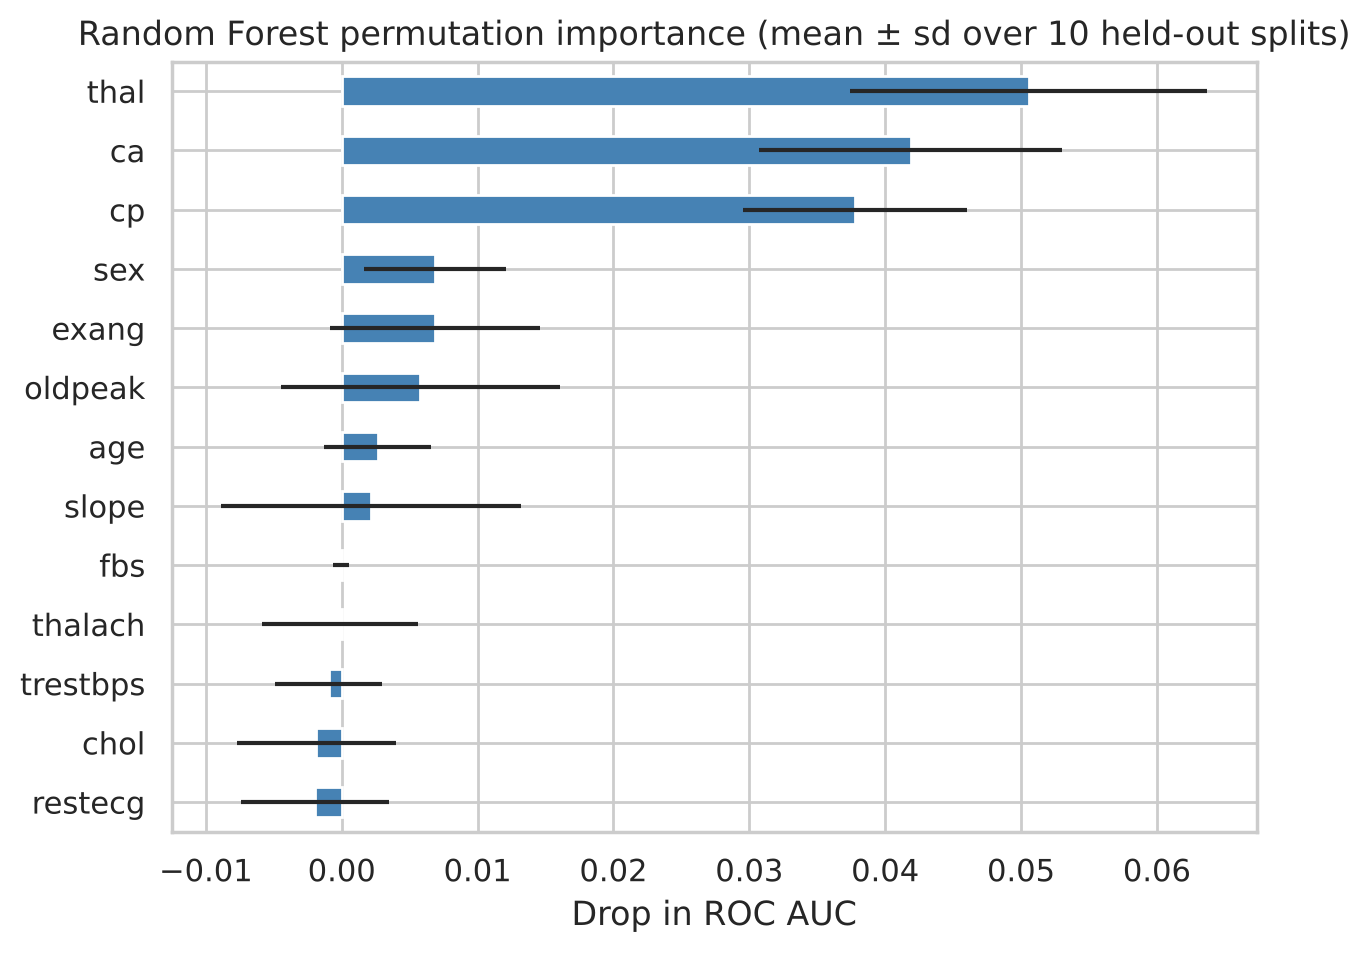

In [11]:
imp_df = pd.DataFrame(imp_runs, columns=X.columns)
imp_s = imp_df.mean().sort_values()
imp_s.plot.barh(figsize=(7, 5), color="steelblue", xerr=imp_df.std()[imp_s.index])
plt.title("Random Forest permutation importance (mean ± sd over 10 held-out splits)"); plt.xlabel("Drop in ROC AUC"); plt.show()

### Predicting a new patient
In the original notebook the "new patient" cell scaled the patient but then predicted on the first rows of `X_test` instead, so the patient was never actually classified. Here the pipeline takes the patient directly and returns the probability of **heart disease**.

In [12]:
patient = pd.DataFrame([[52, 1, 1, 129, 241, 0, 1, 159, 0, 0.6, 2, 0, 2]], columns=X.columns)
p = final.predict_proba(patient)[0, 1]
print(f"Predicted: {'heart disease' if p >= 0.5 else 'no heart disease'}  |  probability of heart disease: {p:.2f}")

Predicted: no heart disease  |  probability of heart disease: 0.03


## 7. Conclusions

In [13]:
r = cv_table.loc[best_name]
gap = abs(np.mean(rob["Logistic Regression"]) - np.mean(rob["Random Forest"]))
print(f'''1. Data quality: {n_dup} of {len(raw)} rows ({n_dup/len(raw):.0%}) were exact duplicates; only {len(df)} unique patients remain.
2. The `target` column is reversed in this file (1 = no disease); it was corrected before modelling so that sensitivity refers to sick patients.
3. The ~90% accuracy of the naive split is mostly leakage (identical rows in train and test). On clean data the same unscaled KNN is far worse.
4. With scaling, proper CV and deduplicated data, the models reach about {cv_table.accuracy.min():.0%}-{cv_table.accuracy.max():.0%} CV accuracy (majority baseline {max(y.mean(), 1 - y.mean()):.0%}).
5. Selected model: {best_name} (CV accuracy {r.accuracy:.2f}, sensitivity {r.sensitivity:.2f}, specificity {r.specificity:.2f}, ROC AUC {r.roc_auc:.2f}); single-split test accuracy {accuracy_score(y_test, pred):.2f} (10-split average {np.mean(rob_acc[best_name]):.2f}).
6. Most influential features: {", ".join(imp_s.index[::-1][:3])}.
7. Over 10 random splits, Logistic Regression and Random Forest differ by only {gap:.3f} test AUC on average: treat them as equivalent, do not over-interpret the ranking.

Limitations: only {len(df)} patients, so estimates are noisy and the test set is small; no external validation.
This is a learning project, not a medical tool.''')

1. Data quality: 723 of 1026 rows (70%) were exact duplicates; only 303 unique patients remain.
2. The `target` column is reversed in this file (1 = no disease); it was corrected before modelling so that sensitivity refers to sick patients.
3. The ~90% accuracy of the naive split is mostly leakage (identical rows in train and test). On clean data the same unscaled KNN is far worse.
4. With scaling, proper CV and deduplicated data, the models reach about 83%-84% CV accuracy (majority baseline 54%).
5. Selected model: Random Forest (CV accuracy 0.84, sensitivity 0.79, specificity 0.89, ROC AUC 0.92); single-split test accuracy 0.84 (10-split average 0.82).
6. Most influential features: thal, ca, cp.
7. Over 10 random splits, Logistic Regression and Random Forest differ by only 0.003 test AUC on average: treat them as equivalent, do not over-interpret the ranking.

Limitations: only 303 patients, so estimates are noisy and the test set is small; no external validation.
This is a learning 